In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings

# Apply a default style for plots
sns.set(style="whitegrid")
warnings.filterwarnings('ignore')


In [31]:
# Load the dataset
file_path = 'Set 2-heart_disease.csv'
try:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully.")
    print(f"Original shape: {df.shape}")
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found.")
    print("Please make sure the CSV file is in the same directory as this notebook.")
    # Create an empty dataframe to avoid further errors
    df = pd.DataFrame()


Dataset loaded successfully.
Original shape: (1025, 14)


In [32]:
if not df.empty:
    # Check for duplicates
    duplicate_count = df.duplicated().sum()
    print(f"Found {duplicate_count} duplicate rows.")
    
    # Remove duplicates
    df = df.drop_duplicates()
    print(f"Shape after removing duplicates: {df.shape}")
    
    # Check for missing values
    print("\nMissing values per column:")
    print(df.isnull().sum())

Found 230 duplicate rows.
Shape after removing duplicates: (795, 14)

Missing values per column:
age         50
sex         51
cp          51
trestbps    48
chol        51
fbs         50
restecg     49
thalach     50
exang       51
oldpeak     51
slope       50
ca          51
thal        51
target      50
dtype: int64


In [33]:
if not df.empty:
    # Define numerical and categorical columns based on the dataset description
    numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
    categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

    # Impute numerical columns with median
    for col in numerical_cols:
        if col in df.columns and df[col].isnull().any():
            median_val = df[col].median()
            df[col] = df[col].fillna(median_val)
            print(f"Filled missing values in '{col}' with median: {median_val}")

    # Impute categorical columns with mode
    for col in categorical_cols:
        if col in df.columns and df[col].isnull().any():
            # .mode()[0] gets the first mode in case there are multiple
            mode_val = df[col].mode()[0]
            df[col] = df[col].fillna(mode_val)
            print(f"Filled missing values in '{col}' with mode: {mode_val}")

    print("\nMissing values check after imputation:")
    print(df.isnull().sum().sum())
    
    # Store the cleaned data in a new variable for clarity
    df_cleaned = df.copy()
    print("\nCleaned dataset summary:")
    df_cleaned.info()


Filled missing values in 'age' with median: 55.0
Filled missing values in 'trestbps' with median: 130.0
Filled missing values in 'chol' with median: 240.0
Filled missing values in 'thalach' with median: 153.0
Filled missing values in 'oldpeak' with median: 0.8
Filled missing values in 'sex' with mode: 1.0
Filled missing values in 'cp' with mode: 0.0
Filled missing values in 'fbs' with mode: 0.0
Filled missing values in 'restecg' with mode: 0.0
Filled missing values in 'exang' with mode: 0.0
Filled missing values in 'slope' with mode: 1.0
Filled missing values in 'ca' with mode: 0.0
Filled missing values in 'thal' with mode: 2.0
Filled missing values in 'target' with mode: 1.0

Missing values check after imputation:
0

Cleaned dataset summary:
<class 'pandas.core.frame.DataFrame'>
Index: 795 entries, 0 to 1023
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       795 non-null    float64
 1   sex       795 non-null  

In [34]:
if not df_cleaned.empty:
    stats_cols = ['age', 'chol', 'trestbps']
    stats_summary = pd.DataFrame(index=['Mean', 'Median', 'Mode', 'Std Dev', 'Range', 'Min', 'Max'])

    for col in stats_cols:
        mean = df_cleaned[col].mean()
        median = df_cleaned[col].median()
        mode = df_cleaned[col].mode()[0]  # Get the first mode
        std_dev = df_cleaned[col].std()
        min_val = df_cleaned[col].min()
        max_val = df_cleaned[col].max()
        range_val = max_val - min_val
        
        stats_summary[col] = [mean, median, mode, std_dev, range_val, min_val, max_val]

    print("Descriptive Statistics:")
    print(stats_summary.round(2))


Descriptive Statistics:
           age    chol  trestbps
Mean     54.40  245.48    131.70
Median   55.00  240.00    130.00
Mode     55.00  240.00    130.00
Std Dev   8.75   50.53     17.27
Range    48.00  438.00    106.00
Min      29.00  126.00     94.00
Max      77.00  564.00    200.00


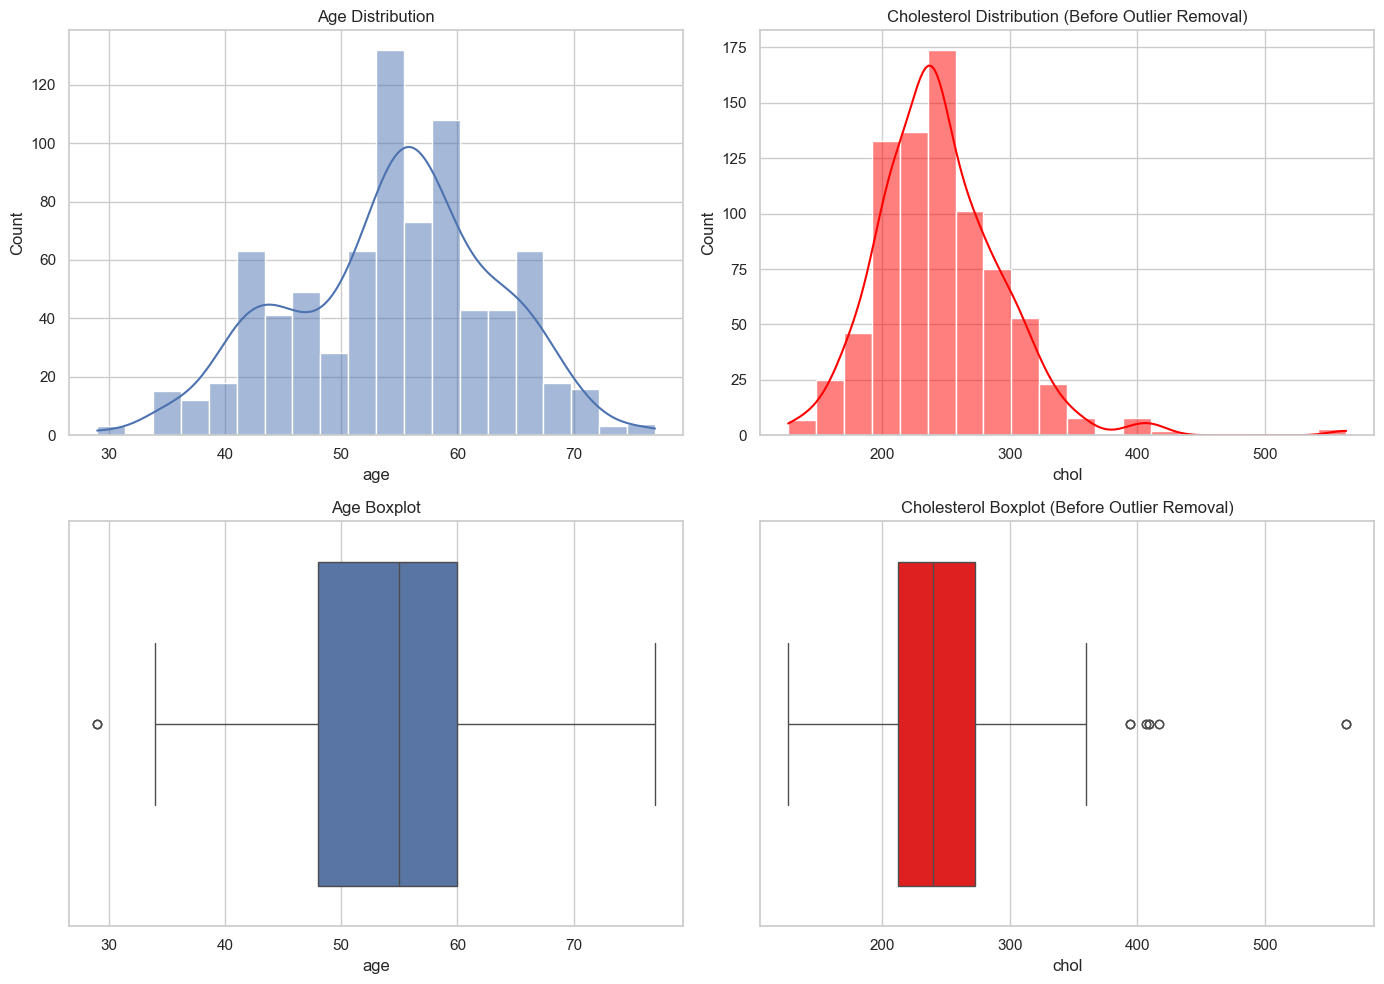

In [35]:
if not df_cleaned.empty:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Age plots
    sns.histplot(df_cleaned['age'], kde=True, ax=axes[0, 0], bins=20)
    axes[0, 0].set_title('Age Distribution')
    sns.boxplot(x=df_cleaned['age'], ax=axes[1, 0])
    axes[1, 0].set_title('Age Boxplot')

    # Cholesterol plots
    sns.histplot(df_cleaned['chol'], kde=True, ax=axes[0, 1], bins=20, color='red')
    axes[0, 1].set_title('Cholesterol Distribution (Before Outlier Removal)')
    sns.boxplot(x=df_cleaned['chol'], ax=axes[1, 1], color='red')
    axes[1, 1].set_title('Cholesterol Boxplot (Before Outlier Removal)')

    plt.tight_layout()
    plt.show()


Cholesterol IQR: 61.00
Outlier Bounds: Lower = 120.50, Upper = 364.50

Original rows: 795
Rows after removing chol outliers: 782
Rows removed: 13


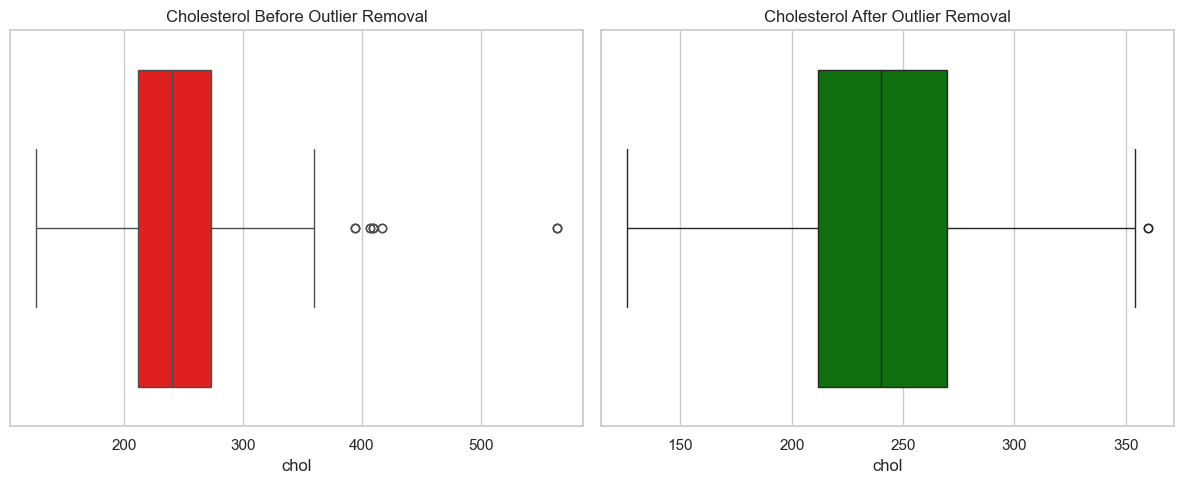

In [36]:
if not df_cleaned.empty:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile) for chol
    Q1 = df_cleaned['chol'].quantile(0.25)
    Q3 = df_cleaned['chol'].quantile(0.75)

    # Calculate the Interquartile Range (IQR)
    IQR = Q3 - Q1

    # Define the outlier bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"Cholesterol IQR: {IQR:.2f}")
    print(f"Outlier Bounds: Lower = {lower_bound:.2f}, Upper = {upper_bound:.2f}")

    # Create a new DataFrame without the outliers
    df_no_outliers = df_cleaned[(df_cleaned['chol'] >= lower_bound) & (df_cleaned['chol'] <= upper_bound)]

    print(f"\nOriginal rows: {df_cleaned.shape[0]}")
    print(f"Rows after removing chol outliers: {df_no_outliers.shape[0]}")
    print(f"Rows removed: {df_cleaned.shape[0] - df_no_outliers.shape[0]}")

    # Show before-and-after boxplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    sns.boxplot(x=df_cleaned['chol'], ax=axes[0], color='red')
    axes[0].set_title('Cholesterol Before Outlier Removal')
    
    sns.boxplot(x=df_no_outliers['chol'], ax=axes[1], color='green')
    axes[1].set_title('Cholesterol After Outlier Removal')
    
    plt.tight_layout()
    plt.show()

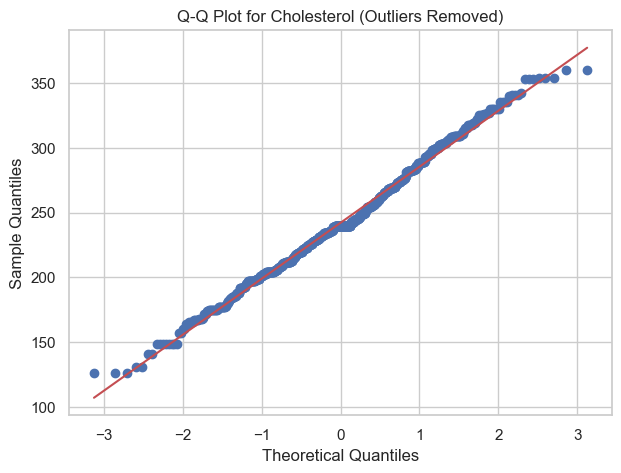

In [37]:
if 'df_no_outliers' in locals():
    plt.figure(figsize=(7, 5))
    stats.probplot(df_no_outliers['chol'], dist="norm", plot=plt)
    plt.title('Q-Q Plot for Cholesterol (Outliers Removed)')
    plt.xlabel('Theoretical Quantiles')
    plt.ylabel('Sample Quantiles')
    plt.show()


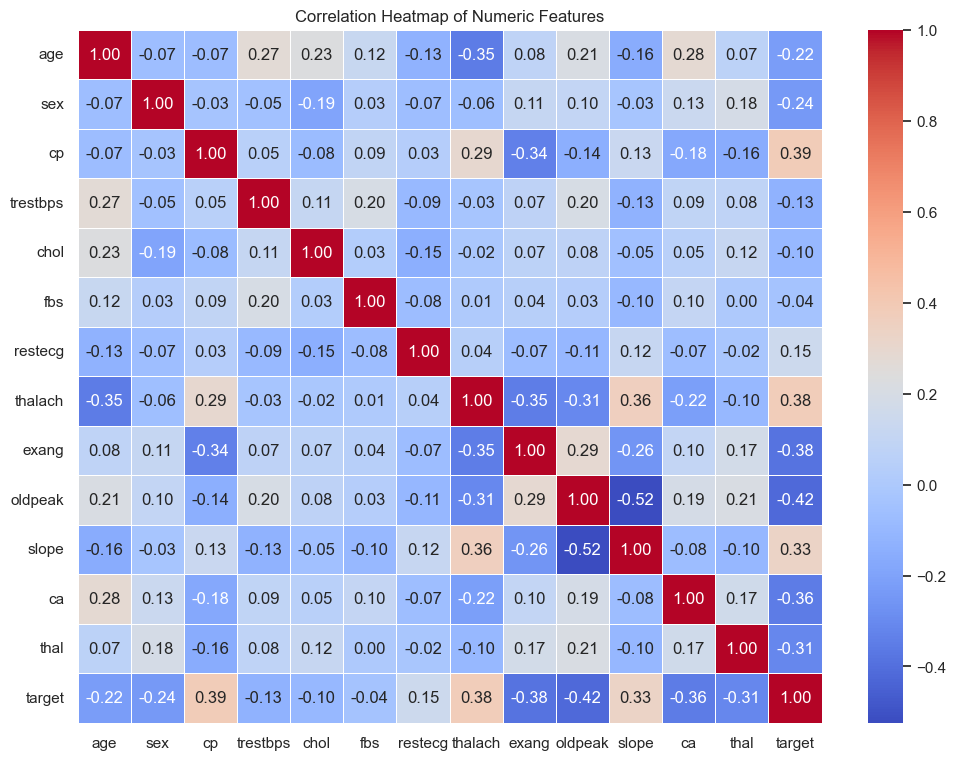


Correlations with Age:
age         1.000000
ca          0.283134
trestbps    0.273059
chol        0.227328
oldpeak     0.213897
fbs         0.122143
exang       0.077424
thal        0.068609
sex        -0.067343
cp         -0.074627
restecg    -0.127748
slope      -0.156732
target     -0.223614
thalach    -0.352474
Name: age, dtype: float64


In [38]:
if not df_cleaned.empty:
    # Select all numeric columns for the correlation matrix
    all_numeric_cols = df_cleaned.select_dtypes(include=np.number).columns
    corr_matrix = df_cleaned[all_numeric_cols].corr()

    plt.figure(figsize=(12, 9))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap of Numeric Features')
    plt.show()
    
    # Print correlations with 'age' specifically
    print("\nCorrelations with Age:")
    print(corr_matrix['age'].sort_values(ascending=False))


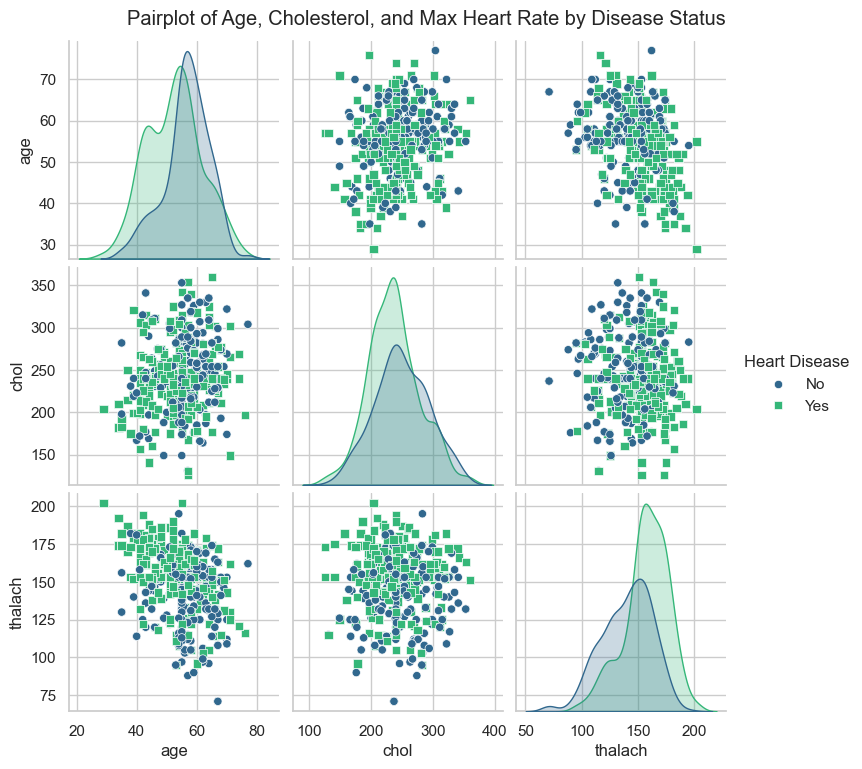

In [39]:
if 'df_no_outliers' in locals():
    pairplot_cols = ['age', 'chol', 'thalach', 'target']
    
    # Map target to readable labels
    plot_df = df_no_outliers.copy()
    plot_df['Heart Disease'] = plot_df['target'].map({0: 'No', 1: 'Yes'})
    
    sns.pairplot(plot_df, vars=['age', 'chol', 'thalach'], hue='Heart Disease', palette='viridis', markers=["o", "s"])
    plt.suptitle('Pairplot of Age, Cholesterol, and Max Heart Rate by Disease Status', y=1.02)
    plt.show()

In [40]:
if 'df_no_outliers' in locals():
    # Separate the two groups
    chol_no_disease = df_no_outliers[df_no_outliers['target'] == 0]['chol']
    chol_disease = df_no_outliers[df_no_outliers['target'] == 1]['chol']

    print(f"Mean Chol (No Disease): {chol_no_disease.mean():.2f}")
    print(f"Mean Chol (Disease): {chol_disease.mean():.2f}")

    # Perform the t-test
    # We should first check for equal variances
    levene_test = stats.levene(chol_no_disease, chol_disease)
    print(f"\nLevene's Test (for equal variances): p-value = {levene_test.pvalue:.4f}")

    # If p-value > 0.05, assume equal variances. If p-value <= 0.05, do not.
    equal_var_flag = levene_test.pvalue > 0.05
    if equal_var_flag:
        print("p > 0.05, variances are equal. Using standard t-test.")
    else:
        print("p <= 0.05, variances are unequal. Using Welch's t-test.")

    t_statistic, p_value = stats.ttest_ind(chol_no_disease, chol_disease, equal_var=equal_var_flag)

    print(f"\nT-test Results:")
    print(f"  T-statistic: {t_statistic:.4f}")
    print(f"  P-value: {p_value:.4f}")

Mean Chol (No Disease): 248.93
Mean Chol (Disease): 236.90

Levene's Test (for equal variances): p-value = 0.0925
p > 0.05, variances are equal. Using standard t-test.

T-test Results:
  T-statistic: 3.9035
  P-value: 0.0001


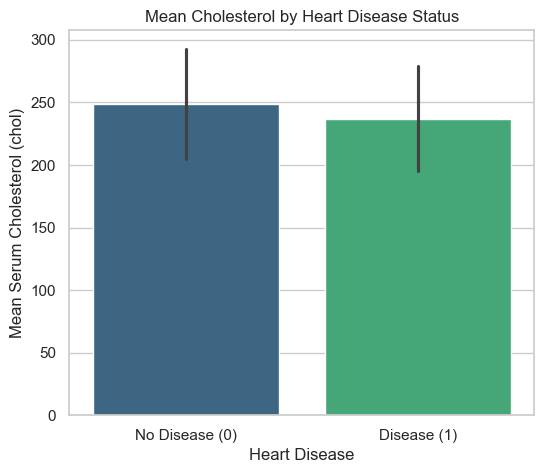

In [41]:
if 'df_no_outliers' in locals():
    plt.figure(figsize=(6, 5))
    sns.barplot(data=df_no_outliers, x='target', y='chol', palette='viridis', errorbar='sd')
    plt.title('Mean Cholesterol by Heart Disease Status')
    plt.xlabel('Heart Disease')
    plt.ylabel('Mean Serum Cholesterol (chol)')
    plt.xticks(ticks=[0, 1], labels=['No Disease (0)', 'Disease (1)'])
    plt.show()


In [42]:
if 'df_no_outliers' in locals():
    # Parameters for Margin of Error
    data = df_no_outliers['chol']
    n = len(data)
    std_dev = data.std()
    z_score = 1.96  # For 95% confidence

    # Calculate Margin of Error (ME)
    margin_of_error = z_score * (std_dev / np.sqrt(n))

    print(f"Sample size (n): {n}")
    print(f"Standard Deviation: {std_dev:.2f}")
    print(f"Z-score (95%): {z_score}")
    print(f"\nMargin of Error (95%): {margin_of_error:.2f}")

Sample size (n): 782
Standard Deviation: 43.19
Z-score (95%): 1.96

Margin of Error (95%): 3.03


In [43]:
if 'chol_disease' in locals():
    # Parameters for CI
    data_disease = chol_disease
    mean_disease = data_disease.mean()
    n_disease = len(data_disease)
    std_err_disease = data_disease.std() / np.sqrt(n_disease)
    z_score = 1.96  # For 95% confidence

    # Calculate Confidence Interval
    lower_ci = mean_disease - (z_score * std_err_disease)
    upper_ci = mean_disease + (z_score * std_err_disease)

    print(f"Mean Cholesterol (Disease): {mean_disease:.2f}")
    print(f"Sample Size (Disease): {n_disease}")
    print(f"Standard Error (Disease): {std_err_disease:.2f}")
    print(f"\n95% Confidence Interval (Disease): [{lower_ci:.2f}, {upper_ci:.2f}]")


Mean Cholesterol (Disease): 236.90
Sample Size (Disease): 437
Standard Error (Disease): 2.00

95% Confidence Interval (Disease): [232.98, 240.82]


In [44]:
if 'chol_disease' in locals():
    # Population mean to test against
    pop_mean_test = 245.0
    
    # Perform one-sample t-test
    t_stat_1samp, p_val_1samp = stats.ttest_1samp(chol_disease, pop_mean_test)

    print(f"One-Sample T-Test (Target = 1 vs. {pop_mean_test} mg/dl)")
    print(f"  Sample Mean: {chol_disease.mean():.2f}")
    print(f"  T-statistic: {t_stat_1samp:.4f}")
    print(f"  P-value: {p_val_1samp:.4f}")


One-Sample T-Test (Target = 1 vs. 245.0 mg/dl)
  Sample Mean: 236.90
  T-statistic: -4.0499
  P-value: 0.0001


In [45]:
if not df_cleaned.empty:
    # Define features (X) and target (y)
    feature_cols = ['age', 'trestbps', 'thalach', 'oldpeak', 'ca']
    target_col = 'chol'
    
    X = df_cleaned[feature_cols]
    y = df_cleaned[target_col]
    
    # Create and fit the model
    # Note: We are fitting on the whole dataset as requested (no train/test split)
    model = LinearRegression()
    model.fit(X, y)
    
    # Make predictions
    y_pred = model.predict(X)
    
    # Report fit metrics
    r2 = r2_score(y, y_pred)
    mse = mean_squared_error(y, y_pred)
    mae = mean_absolute_error(y, y_pred)
    rmse = np.sqrt(mse)

    print("--- Linear Regression Fit Metrics ---")
    print(f"R-squared (R²): {r2:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    
    # Report coefficients
    print("\n--- Model Coefficients ---")
    for i, col in enumerate(feature_cols):
        print(f"  {col}: {model.coef_[i]:.4f}")
    print(f"  Intercept: {model.intercept_:.4f}")


--- Linear Regression Fit Metrics ---
R-squared (R²): 0.0597
Mean Absolute Error (MAE): 36.1125
Mean Squared Error (MSE): 2397.7459
Root Mean Squared Error (RMSE): 48.9668

--- Model Coefficients ---
  age: 1.3729
  trestbps: 0.1153
  thalach: 0.1769
  oldpeak: 1.9186
  ca: -0.4764
  Intercept: 127.5179


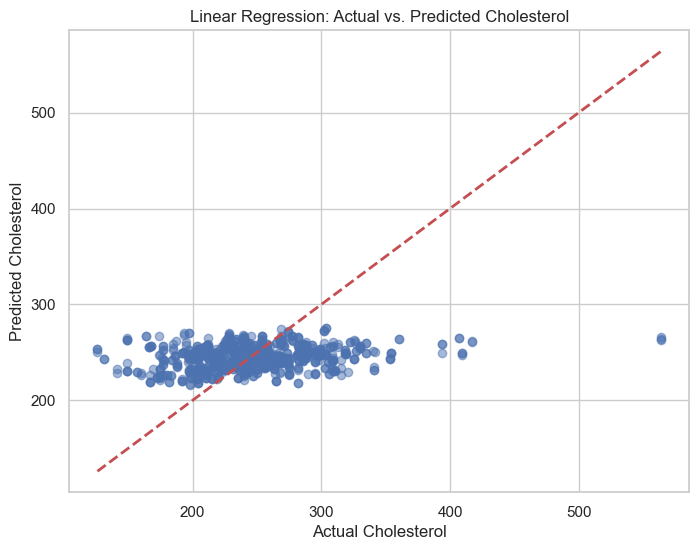

In [46]:
if 'y' in locals():
    plt.figure(figsize=(8, 6))
    plt.scatter(y, y_pred, alpha=0.5)
    
    # Add a line for perfect prediction (y = x)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    
    plt.xlabel('Actual Cholesterol')
    plt.ylabel('Predicted Cholesterol')
    plt.title('Linear Regression: Actual vs. Predicted Cholesterol')
    plt.grid(True)
    plt.show()
